# Experiment No. 10 – Stock Market Prediction using LSTM
**Course:** Deep Learning

**Aim:** Study of Stock Market Prediction using LSTM

| Roll No.: | Name: |
|---|---|
| Class: | Batch: |
| Date of Experiment: | Date of Submission: |

**Dataset:** Google (GOOGL) stock price – training data from Jan 2012 to Dec 2016 (1258 trading days) and test data for Jan 2017 (20 trading days).

**Steps followed:**
1. Load the dataset in the notebook
2. Select the appropriate feature for creating the model from the training data
3. Normalize the features and convert them into time steps of 60
4. Reshape the data (3D array) for applying to the LSTM model
5. Create a sequential LSTM model using Keras
6. Compile the model and train it using the training data
7. Predict using the test data

## B.1 Software Code
### Importing the required libraries

In [1]:
# numpy for arrays, pandas for reading the csv, matplotlib for plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")   # hiding unnecessary warning messages

# MinMaxScaler is used to normalize the data between 0 and 1
from sklearn.preprocessing import MinMaxScaler

# Keras layers needed to build the LSTM model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# fixing the random seed so that results are (almost) the same every run
import tensorflow as tf
np.random.seed(42)
tf.random.set_seed(42)

I0000 00:00:1792138303.887232    3073 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792138303.960803    3073 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792138305.690482    3073 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Step 1: Load the dataset in the notebook

In [2]:
# reading the training and test csv files
# (if the files are downloaded locally, just write the file name instead of the link)
train_url = "https://raw.githubusercontent.com/kevincwu0/rnn-google-stock-prediction/master/Google_Stock_Price_Train.csv"
test_url  = "https://raw.githubusercontent.com/kevincwu0/rnn-google-stock-prediction/master/Google_Stock_Price_Test.csv"

dataset_train = pd.read_csv(train_url)
dataset_test  = pd.read_csv(test_url)

# first 5 rows of training data
dataset_train.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"


In [3]:
# shape of the training and test data (rows, columns)
print("Training data shape:", dataset_train.shape)
print("Test data shape    :", dataset_test.shape)

Training data shape: (1258, 6)
Test data shape    : (20, 6)


In [4]:
# basic information about columns and data types
dataset_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1258 entries, 0 to 1257
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1258 non-null   str    
 1   Open    1258 non-null   float64
 2   High    1258 non-null   float64
 3   Low     1258 non-null   float64
 4   Close   1258 non-null   str    
 5   Volume  1258 non-null   str    
dtypes: float64(3), str(3)
memory usage: 59.1 KB


In [5]:
# checking for missing values
print(dataset_train.isnull().sum())

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [6]:
# statistical summary of the training data
dataset_train.describe()

,Open,High,Low
count,1258.000000,1258.000000,1258.000000
mean,533.709833,537.880223,529.007409
std,151.904442,153.008811,150.552807
min,279.120000,281.210000,277.220000
25%,404.115000,406.765000,401.765000
50%,537.470000,540.750000,532.990000
75%,654.922500,662.587500,644.800000
max,816.680000,816.680000,805.140000


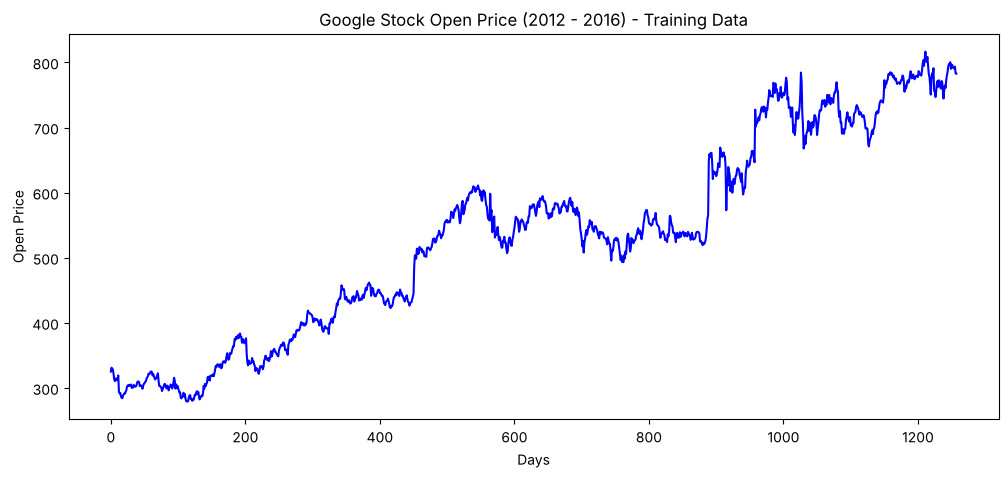

In [7]:
# plotting the opening price of the training data
plt.figure(figsize=(12, 5))
plt.plot(dataset_train['Open'], color='blue')
plt.title('Google Stock Open Price (2012 - 2016) - Training Data')
plt.xlabel('Days')
plt.ylabel('Open Price')
plt.show()

### Step 2: Select the appropriate feature from the training data
We use the **Open** price column as the feature to predict, since we want to predict the opening price of the next day.

In [8]:
# selecting only the 'Open' column (index 1) as a 2D numpy array
training_set = dataset_train.iloc[:, 1:2].values

print(training_set.shape)
print(training_set[:5])

(1258, 1)
[[325.25]
 [331.27]
 [329.83]
 [328.34]
 [322.04]]


### Step 3: Normalize the feature and convert it into time steps of 60
The values are scaled between 0 and 1 using MinMaxScaler. Then for every day, the previous **60 days** of prices are used as input (X) and the price of that day is the output (y).

In [9]:
# normalizing the data between 0 and 1
sc = MinMaxScaler(feature_range=(0, 1))
training_set_scaled = sc.fit_transform(training_set)

print("Before scaling:", training_set[:5].ravel())
print("After scaling :", training_set_scaled[:5].ravel())

Before scaling: [325.25 331.27 329.83 328.34 322.04]
After scaling : [0.08581368 0.09701243 0.09433366 0.09156187 0.07984225]


In [10]:
# creating a data structure with 60 time steps and 1 output
# X_train -> previous 60 days prices, y_train -> next day price
X_train = []
y_train = []

for i in range(60, len(training_set_scaled)):
    X_train.append(training_set_scaled[i-60:i, 0])
    y_train.append(training_set_scaled[i, 0])

# converting lists into numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1198, 60)
y_train shape: (1198,)


### Step 4: Reshape the data (3D array) for applying to the LSTM model
LSTM in Keras needs input in the form **(samples, time steps, features)**.

In [11]:
# reshaping to (number of samples, 60 time steps, 1 feature)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

print("X_train shape after reshape:", X_train.shape)

X_train shape after reshape: (1198, 60, 1)


### Step 5: Create a sequential LSTM model using Keras
4 LSTM layers with 50 units each, Dropout of 0.2 after each LSTM layer to avoid overfitting, and one Dense output layer.

In [12]:
# initializing the sequential model
model = Sequential()

# 1st LSTM layer + dropout (return_sequences=True because another LSTM comes after it)
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

# 2nd LSTM layer + dropout
model.add(LSTM(units=50, return_sequences=True))
model.add(Dropout(0.2))

# 3rd LSTM layer + dropout
model.add(LSTM(units=50, return_sequences=True))
model.add(Dropout(0.2))

# 4th LSTM layer + dropout (last LSTM, so return_sequences=False)
model.add(LSTM(units=50))
model.add(Dropout(0.2))

# output layer with 1 neuron (predicted price)
model.add(Dense(units=1))

# summary of the model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 60, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,051 (277.54 KB)

 Trainable params: 71,051 (277.54 KB)

 Non-trainable params: 0 (0.00 B)

### Step 6: Compile the model and train it using the training data
Optimizer: **Adam**, Loss: **Mean Squared Error** (since this is a regression problem).

In [13]:
# compiling the model
model.compile(optimizer='adam', loss='mean_squared_error')

# training the model for 100 epochs with batch size 32
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=2)

Epoch 1/100


38/38 - 11s - 288ms/step - loss: 0.0493


Epoch 2/100


38/38 - 5s - 123ms/step - loss: 0.0068


Epoch 3/100


...

38/38 - 5s - 121ms/step - loss: 0.0015


Epoch 99/100


38/38 - 5s - 119ms/step - loss: 0.0015


Epoch 100/100


38/38 - 5s - 121ms/step - loss: 0.0015


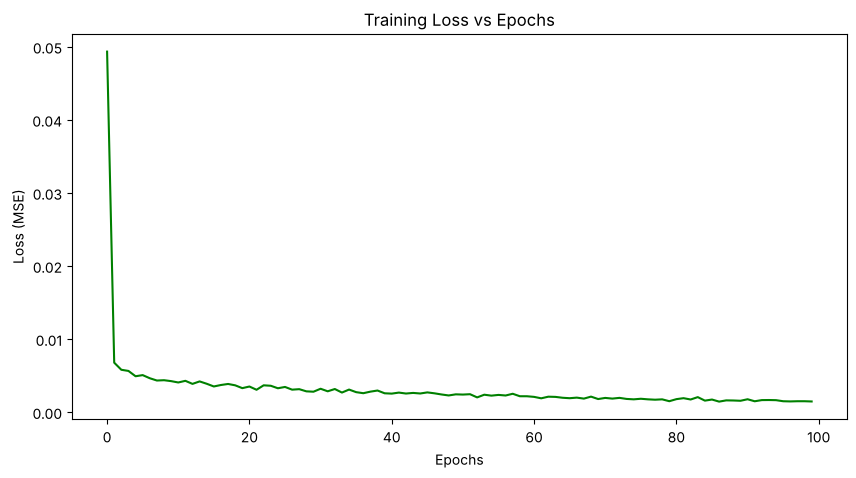

In [14]:
# plotting training loss vs epochs
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], color='green')
plt.title('Training Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.show()

### Step 7: Predict using the test data
To predict each day of January 2017 we need the previous 60 days, so the last 60 days of the training data are joined with the test data.

In [15]:
# actual (real) open prices of January 2017
real_stock_price = dataset_test.iloc[:, 1:2].values
print("Test data shape:", real_stock_price.shape)

Test data shape: (20, 1)


In [16]:
# joining training and test 'Open' columns
dataset_total = pd.concat((dataset_train['Open'], dataset_test['Open']), axis=0)

# taking the last 60 days of training + all test days
inputs = dataset_total[len(dataset_total) - len(dataset_test) - 60:].values
inputs = inputs.reshape(-1, 1)

# scaling with the SAME scaler used for training (only transform, not fit)
inputs = sc.transform(inputs)
print("Inputs shape:", inputs.shape)

Inputs shape: (80, 1)


In [17]:
# creating the test data structure with 60 time steps
X_test = []
for i in range(60, 60 + len(dataset_test)):
    X_test.append(inputs[i-60:i, 0])

X_test = np.array(X_test)

# reshaping into 3D for the LSTM
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
print("X_test shape:", X_test.shape)

X_test shape: (20, 60, 1)


In [18]:
# predicting the stock price
predicted_stock_price = model.predict(X_test, verbose=0)

# converting the scaled predictions back to original price values
predicted_stock_price = sc.inverse_transform(predicted_stock_price)

In [19]:
# comparing actual and predicted prices in a table
result = pd.DataFrame({
    'Date': dataset_test['Date'],
    'Actual Price': real_stock_price.ravel(),
    'Predicted Price': predicted_stock_price.ravel().astype(float).round(2)
})
result['Difference'] = (result['Actual Price'] - result['Predicted Price']).round(2)
result

,Date,Actual Price,Predicted Price,Difference
0,1/3/2017,778.81,779.63,-0.82
1,1/4/2017,788.36,776.91,11.45
2,1/5/2017,786.08,775.96,10.12
3,1/6/2017,795.26,776.72,18.54
4,1/9/2017,806.40,779.62,26.78
5,1/10/2017,807.86,785.04,22.82
6,1/11/2017,805.00,791.00,14.00
7,1/12/2017,807.14,794.78,12.36
8,1/13/2017,807.48,796.08,11.40
9,1/17/2017,807.08,795.81,11.27


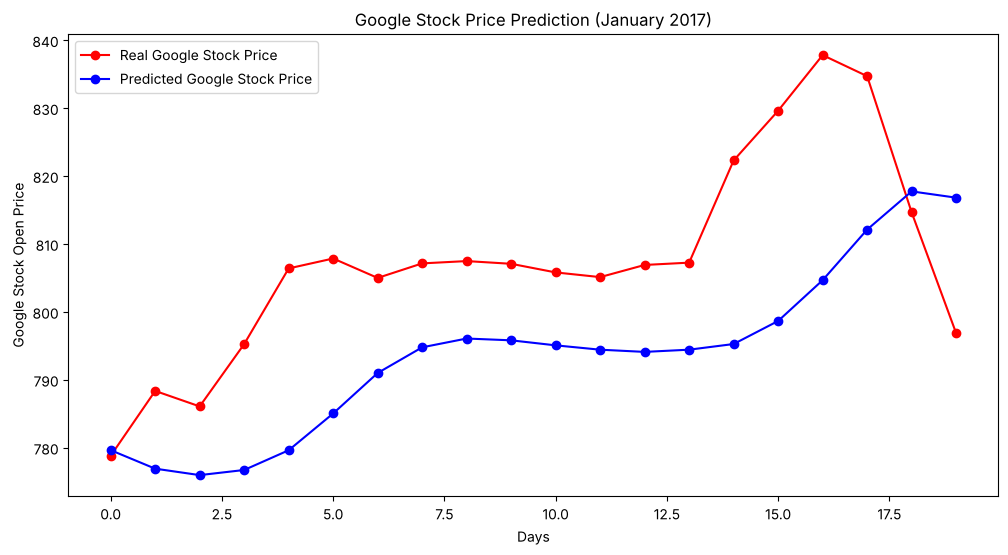

In [20]:
# visualising the results
plt.figure(figsize=(12, 6))
plt.plot(real_stock_price, color='red', marker='o', label='Real Google Stock Price')
plt.plot(predicted_stock_price, color='blue', marker='o', label='Predicted Google Stock Price')
plt.title('Google Stock Price Prediction (January 2017)')
plt.xlabel('Days')
plt.ylabel('Google Stock Open Price')
plt.legend()
plt.show()

### Evaluating the model

In [21]:
# calculating error metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse  = mean_squared_error(real_stock_price, predicted_stock_price)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(real_stock_price, predicted_stock_price)
mape = np.mean(np.abs((real_stock_price - predicted_stock_price) / real_stock_price)) * 100

print("Mean Squared Error (MSE)       :", round(mse, 2))
print("Root Mean Squared Error (RMSE) :", round(rmse, 2))
print("Mean Absolute Error (MAE)      :", round(mae, 2))
print("Mean Absolute % Error (MAPE)   :", round(mape, 2), "%")
print("Average actual price           :", round(real_stock_price.mean(), 2))

Mean Squared Error (MSE)       : 334.25
Root Mean Squared Error (RMSE) : 18.28
Mean Absolute Error (MAE)      : 16.17
Mean Absolute % Error (MAPE)   : 1.99 %
Average actual price           : 807.53


## B.2 Input and Output

**Input:**
- `Google_Stock_Price_Train.csv` – 1258 rows × 6 columns (Date, Open, High, Low, Close, Volume) from 3 Jan 2012 to 30 Dec 2016. No missing values.
- `Google_Stock_Price_Test.csv` – 20 rows × 6 columns for January 2017.
- Feature used: **Open** price only.
- Each input sample = the previous **60 days** of scaled Open prices → final training input shape **(1198, 60, 1)**, target shape **(1198,)**. Test input shape **(20, 60, 1)**.

**Output:**
- Model: 4 LSTM layers (50 units each) + Dropout(0.2) after each + Dense(1) → **71,051 trainable parameters**.
- Training loss (MSE on scaled data) dropped from about **0.049** in epoch 1 to about **0.0015** at epoch 100.
- Predicted Open prices for the 20 days of January 2017 (table and graph above).
- Error on test data: **RMSE ≈ 18.28**, **MAE ≈ 16.17**, **MAPE ≈ 1.99 %** (average actual price ≈ 807.53).
- No errors occurred while running the program.

*(Note: LSTM training has some randomness, so the exact numbers may change slightly every time the notebook is re-run.)*

## B.3 Observations and Learning

**Observations:**
1. The training data shows a clear upward trend – the Open price rose from around 280–330 in 2012 to around 800 by the end of 2016.
2. Normalizing with MinMaxScaler brought all prices into the 0–1 range, which helps the LSTM train faster and more stably.
3. The training loss fell sharply in the first few epochs (0.049 → ~0.005) and then decreased slowly to ~0.0015, so the model learned the pattern without the loss diverging.
4. The predicted curve follows the **overall trend** of the real price (rise in the first week, flat in the middle, rise around 24–27 Jan, then fall).
5. The predictions **lag behind** the actual price by a few days and are smoother. Sudden jumps (like 822 → 837 around 24–26 Jan) and the sudden drop at the end of the month were not captured exactly – the model reacts only after the change shows up in the last 60 days.
6. The predicted values were mostly slightly lower than the actual values, because the test prices (~800–838) were close to or above the highest prices seen during training.
7. The MAPE of about 2 % means that on average the prediction was within ~2 % of the real price, which is good for a model that uses only one feature.

**Learning:**
1. Learned how to prepare time-series data for an LSTM by creating sliding windows of 60 time steps.
2. Learned that an LSTM needs a 3D input of shape (samples, time steps, features).
3. Learned the use of `return_sequences=True` when stacking LSTM layers, and Dropout to reduce overfitting.
4. Learned that the test data must be scaled with the **same** scaler fitted on the training data (only `transform`, not `fit_transform`), and that the last 60 days of the training data are needed to predict the first test day.
5. Learned to use `inverse_transform` to convert scaled predictions back to real prices and to evaluate them using MSE, RMSE, MAE and MAPE.

## B.4 Conclusion

In this experiment, a stacked LSTM model was built using Keras to predict the Google stock opening price. The Open price was selected as the feature, normalized, converted into sequences of 60 time steps and reshaped into a 3D array. The model was compiled with the Adam optimizer and mean squared error loss and trained for 100 epochs. On the January 2017 test data, the model was able to follow the general trend of the stock price with a mean absolute percentage error of about 2 %. However, it could not predict sudden spikes and drops accurately and its predictions lagged behind the real price. This shows that LSTMs are useful for learning trends in time-series data, but stock prices are also affected by outside factors (news, events, market sentiment), so using more features (High, Low, Close, Volume) and more data could improve the results.